[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D1_C3_NB06b_branching_processes.ipynb)

# Day 1 · Chapter 3 · Notebook 06b — Branching processes: one spike, many neurons, and the value of balance

**The question.** When a neuron fires, it can make other neurons fire. Those can make others fire, and so on. How
can a signal travel through many neurons **without dying out and without exploding**? And why would the brain care?

We follow the thought experiment that opens Shew & Plenz (2013), *The functional benefits of criticality in the
cortex*, and build it up step by step:

1. one spike and a biased coin: what "a neuron activates another with probability $p$" means;
2. the thought experiment: 100 neurons, all connected to each other, three guesses for $p$;
3. counting generations: why $p = 1/N$ is special (a **branching process**);
4. *Explore* the 100 neurons yourself;
5. three regimes and a **phase transition** (and its link to the mean-field models of NB05–NB06);
6. ongoing activity of a bigger network: **quiet, aperiodic bursts, asynchronous firing, a rhythm**, the same
   regimes as the active rotators of NB06;
7. from a ball of neurons to a sheet of cortex (a **cellular automaton**);
8. **neuronal avalanches** and power laws: what they are, and why they matter;
9. three functional benefits of balance: **dynamic range**, **information transmission**, **repertoire**;
10. back to real brains: how this is tested in experiments.

No new equations beyond high-school probability. Every model in this notebook is written in plain Python in the
cells, so you can read the rule that generates every figure.

**Words we will use** (each one is introduced when it first appears):

| word | meaning here |
|---|---|
| branching ratio $\sigma$ | how many spikes one spike causes, on average |
| branching process | a chain of "parents" and "children", each parent having a random number of children |
| subcritical / critical / supercritical | $\sigma<1$ (activity dies), $\sigma=1$ (balanced), $\sigma>1$ (activity explodes) |
| cellular automaton | many simple units with a few states (on/off), updated in steps by a local rule |
| absorbing state | a state the system cannot leave by itself (here: total silence) |
| avalanche | a cascade of activity that starts from silence and ends in silence |
| power law | $P(s)\propto s^{-\tau}$: a distribution with no typical size |

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from matplotlib import animation
from matplotlib.colors import ListedColormap
from src.plotting import show_movie
os.makedirs('../figures/videos', exist_ok=True)
REG = {"sub": "C0", "crit": "k", "super": "C3"}      # colours used throughout: blue / black / red

## 1. One spike and a biased coin

A real synapse is unreliable. When neuron A fires, neuron B (one of its targets) may or may not fire as a
consequence. Whether it does depends on many things: how strong the synapse is, how many vesicles are released, how
close B already is to its threshold, how much inhibition B receives at that moment, the level of neuromodulators
(dopamine, acetylcholine, ...).

Shew & Plenz lump all of these into **one number**:

> $p$ = the probability that one spike of A makes B fire.

So each spike is like a set of **biased coin flips**, one for every target neuron, each landing "fire" with
probability $p$. If A talks to $N-1$ other neurons, the number of neurons it makes fire (its **children**) is random,
and on average it is

$$
\sigma \;=\; p\,(N-1).
$$

$\sigma$ (sigma) is called the **branching ratio**: the average number of children per spike. It is the one number
that matters in the rest of the notebook.

Below: one spiking neuron and its 99 targets. We flip the 99 coins for three values of $p$.

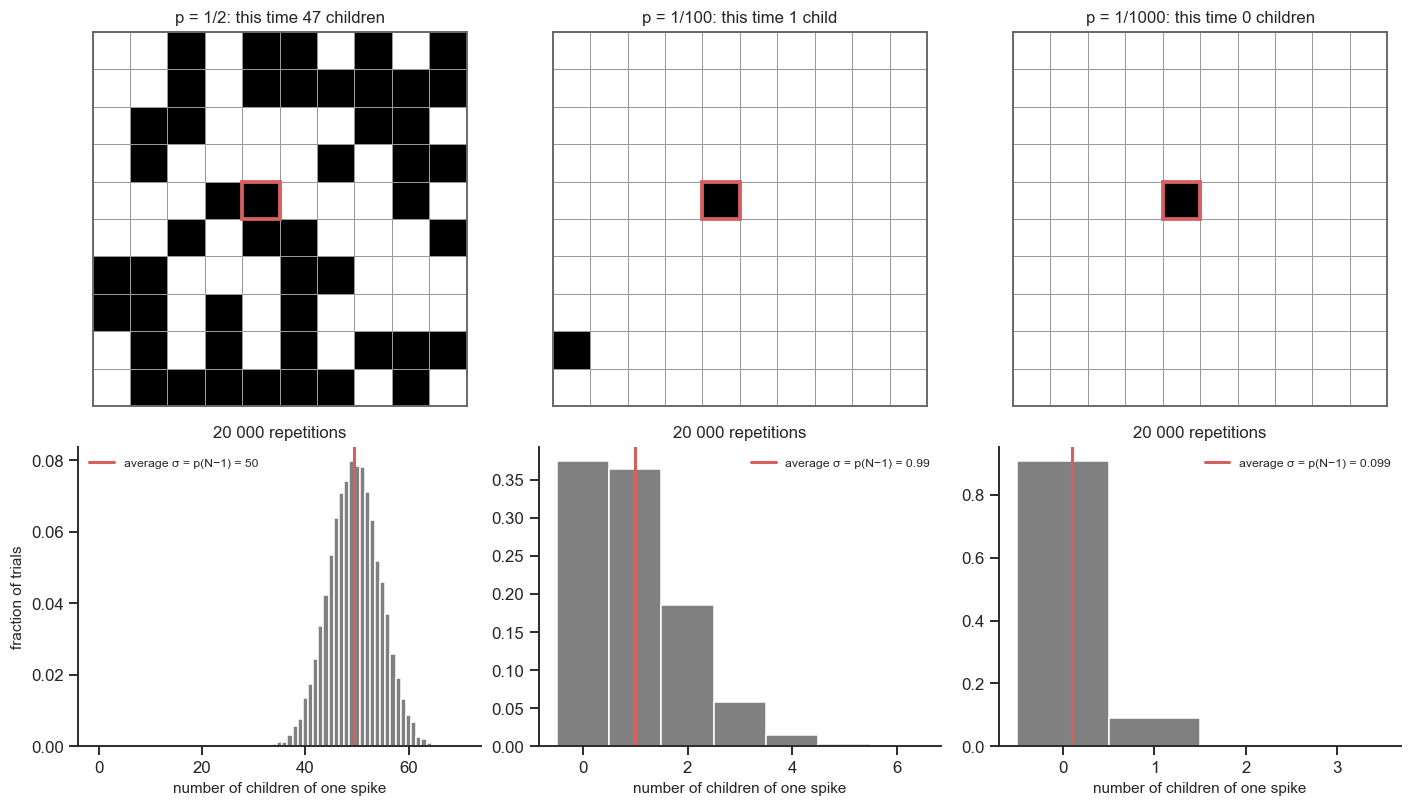

In [2]:
rng = np.random.default_rng(1)
N = 100
P_GUESSES = {"p = 1/2": 1 / 2, "p = 1/100": 1 / 100, "p = 1/1000": 1 / 1000}
GRID_CMAP = ListedColormap(["white", "0.72", "black"])       # 0 = off, 1 = resting (spiked one step ago), 2 = spiking

def draw_grid(ax, cells, mark=None):
    # cells: 100 values (0 off, 1 resting, 2 spiking), drawn as a 10 x 10 grid; mark = a cell framed in red
    ax.pcolormesh(np.asarray(cells).reshape(10, 10)[::-1], cmap=GRID_CMAP, vmin=0, vmax=2, edgecolors="0.6", linewidth=0.5)
    if mark is not None:
        r, c = divmod(mark, 10)
        ax.add_patch(plt.Rectangle((c, 9 - r), 1, 1, fill=False, ec="C3", lw=2.5))
    ax.set(aspect="equal", xticks=[], yticks=[])
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("0.4")

SOURCE = 44                                                    # the neuron that spikes (any cell would do)
fig, ax = plt.subplots(2, 3, figsize=(13, 7.5), gridspec_kw=dict(height_ratios=[1.25, 1]))
for j, (name, p) in enumerate(P_GUESSES.items()):
    fired = rng.random(N) < p                                  # one coin flip for each of the other neurons
    fired[SOURCE] = False
    cells = np.where(fired, 2, 0); cells[SOURCE] = 2
    a = ax[0, j]
    draw_grid(a, cells, mark=SOURCE)
    a.set_title(f"{name}: this time {fired.sum()} " + ("child" if fired.sum() == 1 else "children"))
    # repeat the flips many times: how many children does one spike have?
    children = rng.binomial(N - 1, p, size=20000)
    b = ax[1, j]
    b.hist(children, bins=np.arange(children.max() + 2) - 0.5, color="0.5", density=True)
    b.axvline(p * (N - 1), c="C3", lw=2, label=f"average σ = p(N−1) = {p * (N - 1):.2g}")
    b.set(xlabel="number of children of one spike", ylabel="fraction of trials" if j == 0 else "",
          title="20 000 repetitions"); b.legend(fontsize=8)
plt.tight_layout()

Top row: the 100 neurons as a 10 × 10 grid of cells (every cell is connected to every other cell; the
connections are not drawn). The spiking neuron is the black cell framed in red; the other black cells are the
neurons it made fire; white cells did not fire. Bottom row: the number of children over 20 000 repetitions (grey bars), and its average
$\sigma$ (red line).

* $p=1/2$: one spike makes about **50** neurons fire.
* $p=1/100$: one spike makes about **one** neuron fire (sometimes 0, sometimes 2 or 3).
* $p=1/1000$: one spike almost always makes **nobody** fire ($\sigma\approx0.1$).

The count of children follows a *binomial* distribution (number of "heads" in 99 biased coins). The exact shape will
not matter. Only its average, $\sigma$, will.

## 2. The thought experiment: 100 neurons, all connected

> *"Imagine a small piece of cortex including 100 neurons that are completely interconnected. The only additional
> detail that we will consider is the propensity of one action potential to cause another."* (Shew & Plenz 2013)

The rules of the game:

1. Time advances in **steps** (think of one step as a few milliseconds, the time for a spike to cross a synapse
   and trigger the next one).
2. Each neuron is either **on** (spiking in this step) or **off**.
3. At the next step, every neuron that is off flips one coin for each neuron that is on now. If **at least one** coin
   says "fire", it fires. With $A$ neurons on, the probability is $1-(1-p)^{A}$.
4. A neuron that has just spiked must rest for one step (**refractory period**), so it cannot fire twice in a row.

A system made of many identical units with a few discrete states (on/off), updated in discrete steps by a simple
local rule, is called a **cellular automaton**. Ours uses coins, so it is a **probabilistic cellular automaton**.
(Wolfram and others studied cellular automata in the 1980s; some of them turned out to compute best close to a
critical point, which is where this story started.)

The whole model is the function below.

In [3]:
def step_all_to_all(spiking, p, rng, ext=0.0):
    # One time step of the thought experiment. spiking: True/False for each neuron (True = spiking now).
    # ext: outside input, the expected number of spikes per step coming from outside the network (0 until section 4)
    A = spiking.sum()                            # how many neurons are spiking now
    P_fire = 1 - (1 - ext / len(spiking)) * (1 - p) ** A   # at least one "fire": from the A neurons or from outside
    can_fire = ~spiking                          # a neuron that spikes now rests at the next step
    return can_fire & (rng.random(len(spiking)) < P_fire)


def run_all_to_all(p, N=100, T=20, seed=0, ext=0.0):
    # Start with ONE spiking neuron and return the on/off state of every neuron at every step: shape (T+1, N).
    rng = np.random.default_rng(seed)
    s = np.zeros(N, bool); s[0] = True
    history = [s]
    for t in range(T):
        s = step_all_to_all(s, p, rng, ext)
        history.append(s)
    return np.array(history)


def pick_run(p, T, min_steps, N=100):
    # Choose a random seed whose cascade lasts at least min_steps steps (only to make a nice picture).
    for seed in range(1000):
        h = run_all_to_all(p, N, T, seed)
        alive = np.nonzero(h.sum(1))[0].max()
        if alive >= min(min_steps, T):
            return h
    return h

runs = {"p = 1/2": pick_run(1 / 2, 30, 30), "p = 1/100": pick_run(1 / 100, 30, 25), "p = 1/1000": pick_run(1 / 1000, 30, 0)}
print({k: v.sum(1)[:12].tolist() for k, v in runs.items()})     # number of spiking neurons in the first steps

{'p = 1/2': [1, 44, 56, 44, 56, 44, 56, 44, 56, 44, 56, 44], 'p = 1/100': [1, 2, 2, 1, 2, 2, 1, 4, 7, 14, 13, 14], 'p = 1/1000': [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


Now we draw the 100 neurons as a grid of cells, one row of grids per guess of $p$, time going from left to right
(the paper's Fig. 1 shows the same experiment with neurons on a circle). **Black** = spiking now, **grey** = spiked at
the previous step (now resting), **white** = off. Remember that every cell talks to every other cell: where a
cell sits on the grid does not matter.

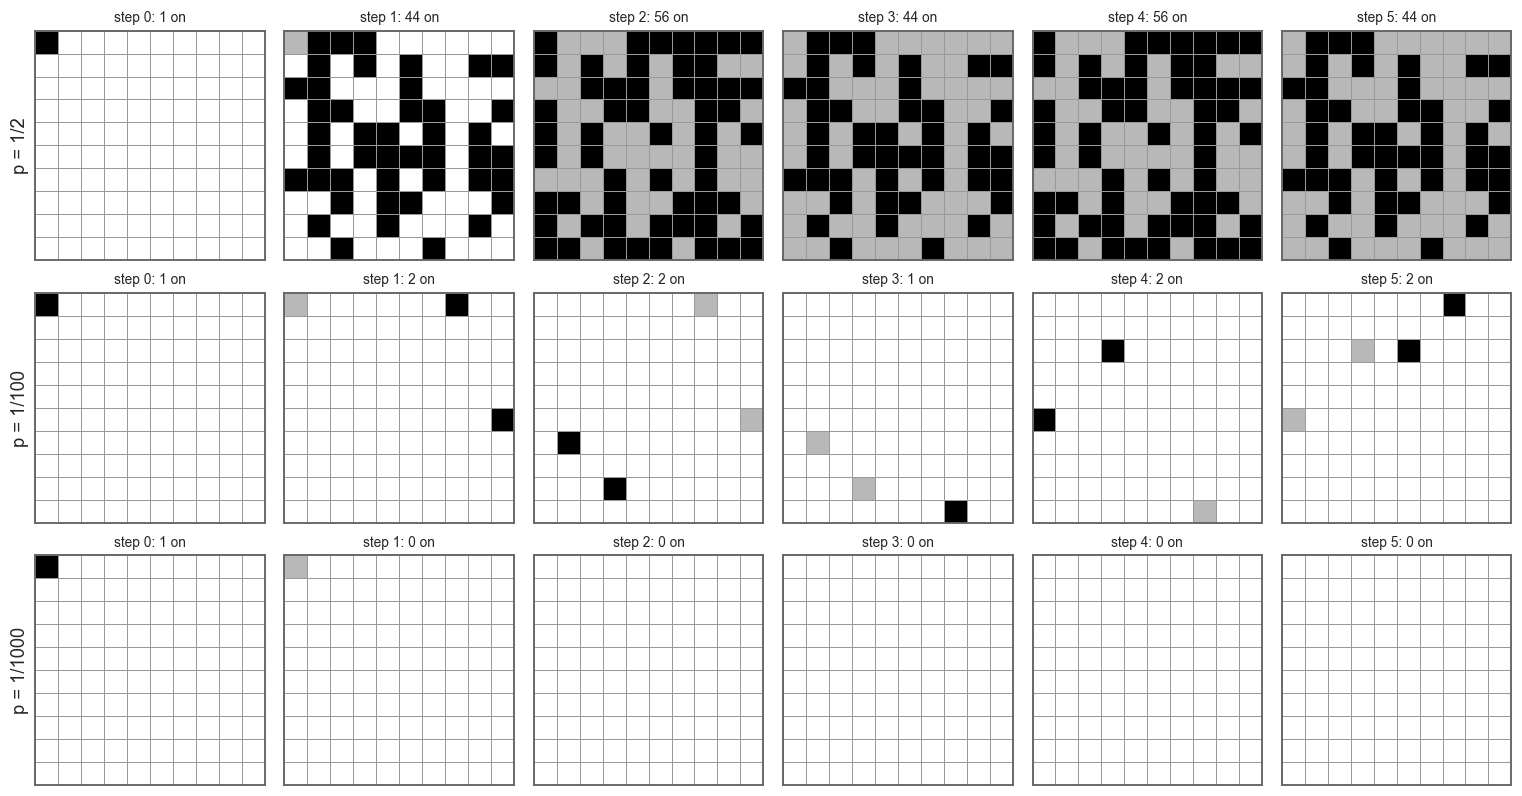

In [4]:
def cell_states(h, t):
    # 0 off, 1 resting (spiked at t-1), 2 spiking at t
    prev = h[t - 1] if t > 0 else np.zeros(h.shape[1], bool)
    return np.where(h[t], 2, np.where(prev, 1, 0))

T_SHOW = 6
fig, ax = plt.subplots(3, T_SHOW, figsize=(14, 7.4))
for r, (name, h) in enumerate(runs.items()):
    for t in range(T_SHOW):
        draw_grid(ax[r, t], cell_states(h, t))
        ax[r, t].set_title(f"step {t}: {h[t].sum()} on", fontsize=9)
    ax[r, 0].set_ylabel(name, fontsize=12)
plt.tight_layout()

Read each row from left to right.

* **$p=1/2$ (top).** One spike makes about half of the network fire. Those 50 spikes make every neuron that is not
  resting fire. The two halves then take turns forever: a runaway **chain reaction** that consumes the whole network.
  Imbalanced.
* **$p=1/1000$ (bottom).** With 100 neurons, about 10 spikes are needed to cause one new spike, on average. A
  single spike causes nothing: the activity dies immediately. Imbalanced the other way.
* **$p=1/100$ (middle).** One spike tends to cause one spike. The activity neither dies at once nor takes over the
  network: it **reverberates**, a few neurons at a time, wandering around the network. This is the balanced case.

**Careful: we picked a lucky run for the middle row** (the paper's Fig. 1 does the same). At $p=1/100$ a single
spike has *no* children 37% of the time, $(1-1/100)^{99}\approx0.37$, so most cascades stop after one or two steps.
"Balanced" does **not** mean that every cascade lasts forever. It means that, *on average*, each spike is replaced by
one spike. Section 3 shows what this implies.

Watch the three cases evolve together:

In [5]:
def grid_movie(runs, T=30):
    fig = plt.figure(figsize=(12, 5.6))
    gs = fig.add_gridspec(2, 3, height_ratios=[3, 1.1])
    axr = [fig.add_subplot(gs[0, j]) for j in range(3)]
    axa = [fig.add_subplot(gs[1, j]) for j in range(3)]
    curs = []
    for j, (name, h) in enumerate(runs.items()):
        axa[j].plot(h.sum(1)[:T + 1], "k", lw=1)
        axa[j].set(xlabel="step", ylabel="neurons on" if j == 0 else "", ylim=(-2, 102), xlim=(0, T))
        curs.append(axa[j].axvline(0, c="C3"))
    plt.tight_layout()

    def update(t):
        for j, (name, h) in enumerate(runs.items()):
            axr[j].cla()
            draw_grid(axr[j], cell_states(h, t))
            axr[j].set_title(f"{name}   (step {t}: {h[t].sum()} on)", fontsize=10)
            curs[j].set_xdata([t, t])
        return curs
    anim = animation.FuncAnimation(fig, update, frames=T + 1, interval=350)
    plt.close(fig)
    return anim

show_movie(grid_movie(runs), save_as="../figures/videos/nb06b_thought_experiment.mp4")

## 3. Counting generations: a branching process

Why is $1/100$ the balanced value? Count generations, as in a family tree.

* Step 0: one spike (the "ancestor").
* Step 1: it has on average $\sigma$ children.
* Step 2: each child has on average $\sigma$ children: $\sigma\times\sigma=\sigma^2$ grandchildren.
* Step $t$: on average $\sigma^t$ spikes (as long as the network is far from full).

$$
\langle A(t)\rangle \approx \sigma^{\,t}, \qquad \sigma = p\,(N-1).
$$

| $p$ | $\sigma$ | after 10 steps, $\sigma^{10}$ |
|---|---|---|
| 1/2 | ≈ 50 | astronomically many: the network saturates after 2 steps |
| 1/100 | ≈ 1 | ≈ 1: activity is preserved |
| 1/1000 | ≈ 0.1 | $10^{-10}$: nothing left |

So **balance means $\sigma=1$, i.e. $p=1/(N-1)\approx 1/N$**: each spike replaces itself, on average. If each neuron
talks to $K$ others (not all of them), the same argument gives $p=1/K$.

This "parents and children" model is called a **branching process** (Galton–Watson process). It was invented in 1874
to ask whether aristocratic family names would die out. It is also the model of a **nuclear chain reaction**: each
fission releases neutrons that trigger, on average, $k$ new fissions. A reactor is called *critical* when $k=1$, and
its control rods absorb neutrons to keep it there. In the cortex, inhibition plays a role similar to the control rods.
The word **critical** comes from this physics.

**A shortcut for speed.** Because every neuron is connected to every other one, the rule only depends on *how many*
neurons are on, $A$, not on *which* ones. Among the $N-A$ neurons that are off, the number that fire is the number
of successes in $N-A$ coins, each with probability $1-(1-p)^A$. So we can simulate just the number $A(t)$:
exactly the same model, without tracking individual neurons. Following a population by a few numbers is the idea
behind the mean-field models of NB05–NB06. This is the simplest case of it.

In [6]:
def run_counts(sigma, N, T, n_runs, A0=1, seed=0):
    # Same model as step_all_to_all, but we only count the active neurons. Many runs in parallel: shape (T+1, n_runs).
    rng = np.random.default_rng(seed)
    p = sigma / (N - 1)
    A = np.full(n_runs, A0)
    out = [A]
    for t in range(T):
        A = rng.binomial(N - A, 1 - (1 - p) ** A)
        out.append(A)
    return np.array(out)

# check: the two versions of the model give the same number of children at step 1
full = [run_all_to_all(1 / 100, T=1, seed=s)[1].sum() for s in range(3000)]
fast = run_counts(0.99, 100, 1, 3000)[1]          # sigma = p (N - 1) = 99/100
print(f"children per spike, p = 1/100:  neuron by neuron {np.mean(full):.3f}   counting only {np.mean(fast):.3f}   (expected 0.99)")

children per spike, p = 1/100:  neuron by neuron 0.996   counting only 0.985   (expected 0.99)


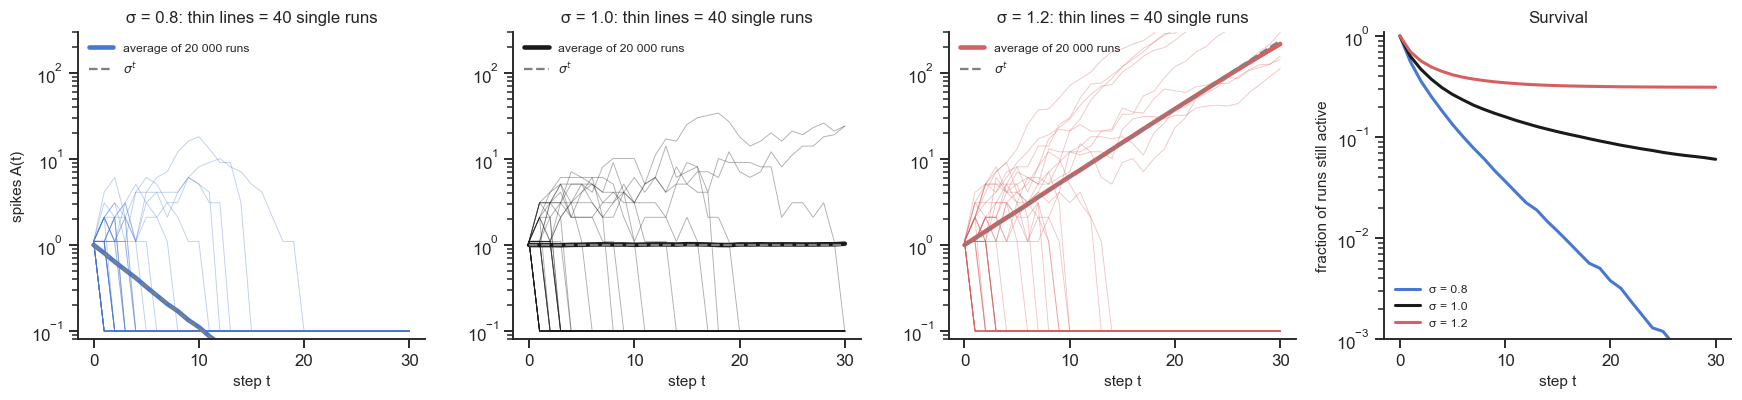

In [7]:
T, N_big = 30, 100_000            # a large network, so that saturation does not interfere with the counting
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
t = np.arange(T + 1)
for j, (sig, key) in enumerate([(0.8, "sub"), (1.0, "crit"), (1.2, "super")]):
    A = run_counts(sig, N_big, T, 20_000, seed=j)
    for k in range(40):
        ax[j].plot(t, A[:, k] + 0.1, c=REG[key], lw=0.6, alpha=0.35)      # +0.1 so that zero is visible on a log axis
    ax[j].plot(t, A.mean(1), c=REG[key], lw=3, label="average of 20 000 runs")
    ax[j].plot(t, sig ** t, "--", c="0.5", lw=1.5, label=r"$\sigma^t$")
    ax[j].set(yscale="log", ylim=(0.08, 300), xlabel="step t", ylabel="spikes A(t)" if j == 0 else "",
              title=f"σ = {sig}: thin lines = 40 single runs")
    ax[j].legend(fontsize=8, loc="upper left")
    ax[3].plot(t, (A > 0).mean(1), c=REG[key], lw=2, label=f"σ = {sig}")
ax[3].set(xlabel="step t", ylabel="fraction of runs still active", title="Survival", yscale="log", ylim=(1e-3, 1.1))
ax[3].legend(fontsize=8)
plt.tight_layout()

Thick lines: the average follows $\sigma^t$ (dashed) in all three cases: it decays for $\sigma=0.8$, stays flat for
$\sigma=1$, grows for $\sigma=1.2$.

But look at the **single runs** (thin lines; runs that died are drawn at the bottom of the axis):

* **$\sigma=1$**: the average is flat, yet *no single run is flat*. Most cascades die within a few steps (right panel):
  about 1 in 3 dies at the first step, 85% are gone after 10 steps, 98% after 100 steps. The few survivors, instead,
  grow large. The flat average is made of many tiny cascades
  plus a few big ones. At balance, the response to one spike is **highly variable**. Shew et al. (2011) found
  this variability to be largest exactly at $\sigma=1$.
* **$\sigma=1.2$**: many cascades still die early by bad luck (a "parent" with zero children). The ones that
  survive the first steps take off.
* **$\sigma=0.8$**: everything dies, and quickly.

Keep this picture in mind: **at balance, a single spike can lead to anything from nothing to a huge cascade, and
most often to almost nothing.** It comes back in section 8 as the power law.

So where does the "reverberating" activity of a critical network come from? From **many** cascades. A real cortex is
never left with one spike: it keeps receiving input from the thalamus, from other areas, and from spontaneous
synaptic release. Each outside spike starts a new cascade. In a critical network these cascades have all sizes and
durations, and together they make irregular, ongoing activity. We add this outside input in the Explore section.

(In the 100-neuron network cascades die even a bit faster than in a huge one: when several neurons are on, some of
the targets are resting or are hit twice in the same step, so the effective $\sigma$ drops slightly below 1.)

### Explore: be the network designer

The 100 all-to-all neurons of section 2, now with a weak **outside input**: on average `outside input` spikes per step
arrive from outside the network (0.05 = one outside spike every 20 steps). Each outside spike can start a cascade.
You set the branching ratio $\sigma$ (so $p=\sigma/99$).

Top: **raster** (one row per neuron, a mark when it spikes). Middle: number of neurons on; the grey ticks at the bottom
are the outside spikes. Right: the **sizes of all the cascades** (avalanches) in this run, from largest to smallest.

* $\sigma=0.5$: does any outside spike start something? How big are the cascades?
* $\sigma=1$: how big is the largest cascade, and the smallest? Change the seed: is it always like this?
* $\sigma=1.5$: what happens after the first outside spike? Is the outside input still needed?
* Set the outside input to 0 (one starting spike only) and $\sigma=1$, then change the seed. Why does the activity
  almost always stop immediately? (Section 3.)

In [8]:
@interact(sigma=slider(1.0, 0.0, 3.0, 0.05, "branching ratio σ"),
          ext=slider(0.05, 0.0, 0.5, 0.01, "outside input (spikes/step)"),
          seed=slider(0, 0, 30, 1, "random seed"))
def explore_branching(sigma, ext, seed):
    T, N = 1000, 100
    rng = np.random.default_rng(int(seed))
    s = np.zeros(N, bool); s[0] = True
    history, outside = [s], []
    for t in range(T):
        A = s.sum()
        from_outside = rng.random(N) < ext / N                  # outside spikes (only quiet neurons can respond)
        from_inside = rng.random(N) < 1 - (1 - sigma / 99) ** A
        s = ~s & (from_outside | from_inside)
        if (~history[-1] & from_outside).any(): outside.append(t + 1)
        history.append(s)
    h = np.array(history); A = h.sum(1)
    # avalanches: stretches of steps with activity, separated by silence
    on = np.r_[0, (A > 0).astype(int), 0]; start, end = np.where(np.diff(on) == 1)[0], np.where(np.diff(on) == -1)[0]
    sizes = np.sort([A[a:b].sum() for a, b in zip(start, end)])[::-1]

    fig = plt.figure(figsize=(15, 5.4))
    gs = fig.add_gridspec(2, 2, width_ratios=[3.2, 1], height_ratios=[2, 1])
    a0 = fig.add_subplot(gs[0, 0]); a1 = fig.add_subplot(gs[1, 0], sharex=a0); a2 = fig.add_subplot(gs[:, 1])
    tt, nn = np.nonzero(h)
    a0.plot(tt, nn, "|", c="k", ms=3, mew=0.8)
    a0.set(ylim=(-1, 100), ylabel="neuron", title=f"σ = {sigma} (p = 1/{99 / max(sigma, 1e-9):.0f}), outside input {ext} spikes/step")
    a1.plot(A, c="C3", lw=0.8)
    a1.plot(outside, np.zeros(len(outside)), "|", c="0.5", ms=8, label="outside spike")
    a1.set(xlabel="step", ylabel="neurons on", ylim=(-1, max(5, 1.1 * A.max())), xlim=(0, T)); a1.legend(fontsize=8, loc="upper right")
    if len(sizes):
        a2.bar(np.arange(len(sizes)), sizes, color="k", width=0.8)
    a2.set(yscale="log", xlabel="cascades, largest first", ylabel="cascade size (spikes)",
           title=f"{len(sizes)} cascade" + ("s" if len(sizes) != 1 else "") + ("" if not len(sizes) or end[-1] <= T else " (last one still running)"))
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='branching ratio σ', layout=…

## 5. Three regimes, one transition

Let us measure, for every $\sigma$, what happens long after a single spike (200 steps):

* the **probability that activity is still alive**;
* the **average fraction of neurons on** at the end.

We repeat this for networks of 100, 1000 and 10 000 neurons.

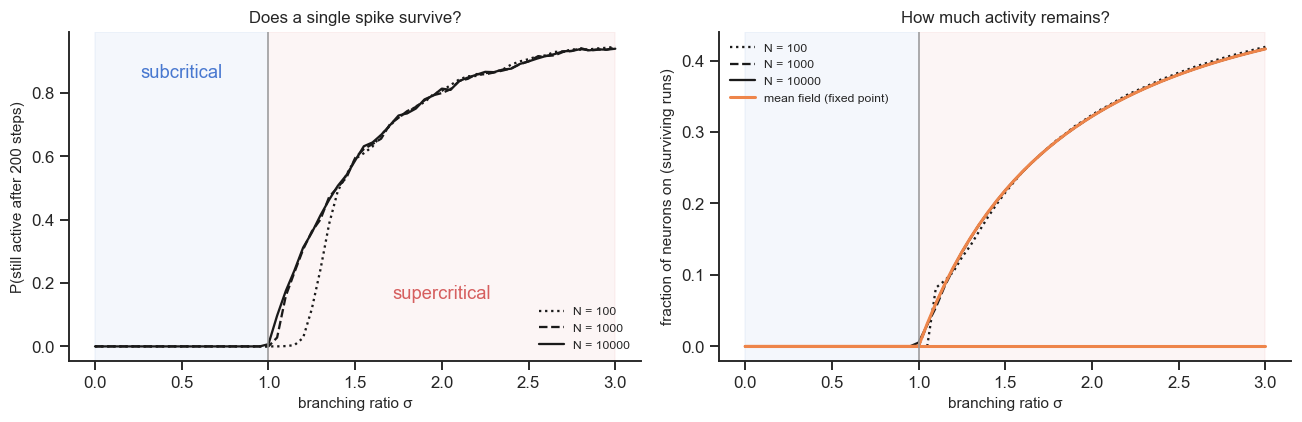

In [9]:
sigmas = np.round(np.arange(0.0, 3.01, 0.05), 2)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for N_, ls in [(100, ":"), (1000, "--"), (10_000, "-")]:
    alive, level = [], []
    for sig in sigmas:
        A = run_counts(sig, N_, 200, 1000)
        alive.append((A[-1] > 0).mean())
        alive_runs = A[-1] > 0
        level.append(A[-20:, alive_runs].mean() / N_ if alive_runs.any() else 0.0)     # among the runs still active
    ax[0].plot(sigmas, alive, "k", ls=ls, label=f"N = {N_}")
    ax[1].plot(sigmas, level, "k", ls=ls, label=f"N = {N_}")

# mean field: fraction a of neurons on, a(t+1) = (1 - a(t)) (1 - exp(-sigma a(t)))
a_star = []
for sig in sigmas:
    a = 0.5
    for _ in range(5000):
        a = 0.5 * a + 0.5 * (1 - a) * (1 - np.exp(-sig * a))   # averaged iteration: converges to the fixed point
    a_star.append(a)
ax[1].plot(sigmas, a_star, c="C1", lw=2, label="mean field (fixed point)")
ax[1].plot(sigmas, np.zeros_like(sigmas), c="C1", lw=2)
for a_ in ax:
    a_.axvline(1, c="0.6", lw=1)
    a_.axvspan(0, 1, color=REG["sub"], alpha=0.06); a_.axvspan(1, 3, color=REG["super"], alpha=0.06)
    a_.set(xlabel="branching ratio σ"); a_.legend(fontsize=8)
ax[0].set(ylabel="P(still active after 200 steps)", title="Does a single spike survive?")
ax[1].set(ylabel="fraction of neurons on (surviving runs)", title="How much activity remains?")
ax[0].text(0.5, 0.85, "subcritical", ha="center", color=REG["sub"]); ax[0].text(2, 0.15, "supercritical", ha="center", color=REG["super"])
plt.tight_layout()

Two **regimes** (shaded) and a sharp border at $\sigma=1$:

* **Subcritical** ($\sigma<1$): every cascade dies. The network always returns to **silence**. Silence is an
  **absorbing state**: once there, the network can never leave it on its own (nobody spikes, so nobody can make
  anybody spike). Only an outside input can restart it.
* **Supercritical** ($\sigma>1$): a single spike has a good chance to ignite **self-sustained activity** that never
  stops.
* **Critical** ($\sigma=1$): exactly at the border.

The survival probability rises continuously from zero at $\sigma=1$; the larger the network, the closer the border
is to exactly $\sigma=1$ (a small network can lose its activity by bad luck even when $\sigma$ is a bit above 1).
This is a **phase transition**, here between an absorbing (silent)
phase and an active phase. (The same mathematics describes iron becoming a magnet below its Curie temperature, or a
disease becoming an epidemic when each patient infects more than one person.)

**Link with bifurcations (NB07).** The orange curve (right) is a mean-field equation for the fraction $a$ of neurons on:
$a(t+1)=(1-a)\,\big(1-e^{-\sigma a}\big)$ (the neurons that are off, times their chance to be hit). For small $a$ it
is just $a(t+1)\approx\sigma\,a(t)$. Silence ($a=0$) is a fixed point; it is stable for $\sigma<1$ and unstable for
$\sigma>1$, where a new branch of active states appears. In the language of dynamical systems this is a
**transcritical bifurcation**. *Critical* in the network = sitting exactly at the bifurcation point of its mean field.
It is the same idea as NB05–NB06, where a population tuned close to a bifurcation responds most to small inputs.

## 6. Ongoing activity: the regimes of NB06 again

In NB06 a population of active rotators could be **quiet**, fire in **aperiodic bursts** of different sizes (at the
border), fire **asynchronously**, or burst **periodically**. Does our much simpler coin-flipping network do the same?

We make three changes, all closer to real neurons:

* a bigger network: $64\times64 = 4096$ neurons, still all connected to each other (so $p=\sigma/4095$);
* after a spike a neuron rests for **4 steps** (refractory period), instead of 1;
* a weak **outside input**: about one outside spike every 10 steps in the whole network.

We let the network run on its own for 1500 steps at four values of $\sigma$. Black = spiking, grey = resting,
white = quiet.

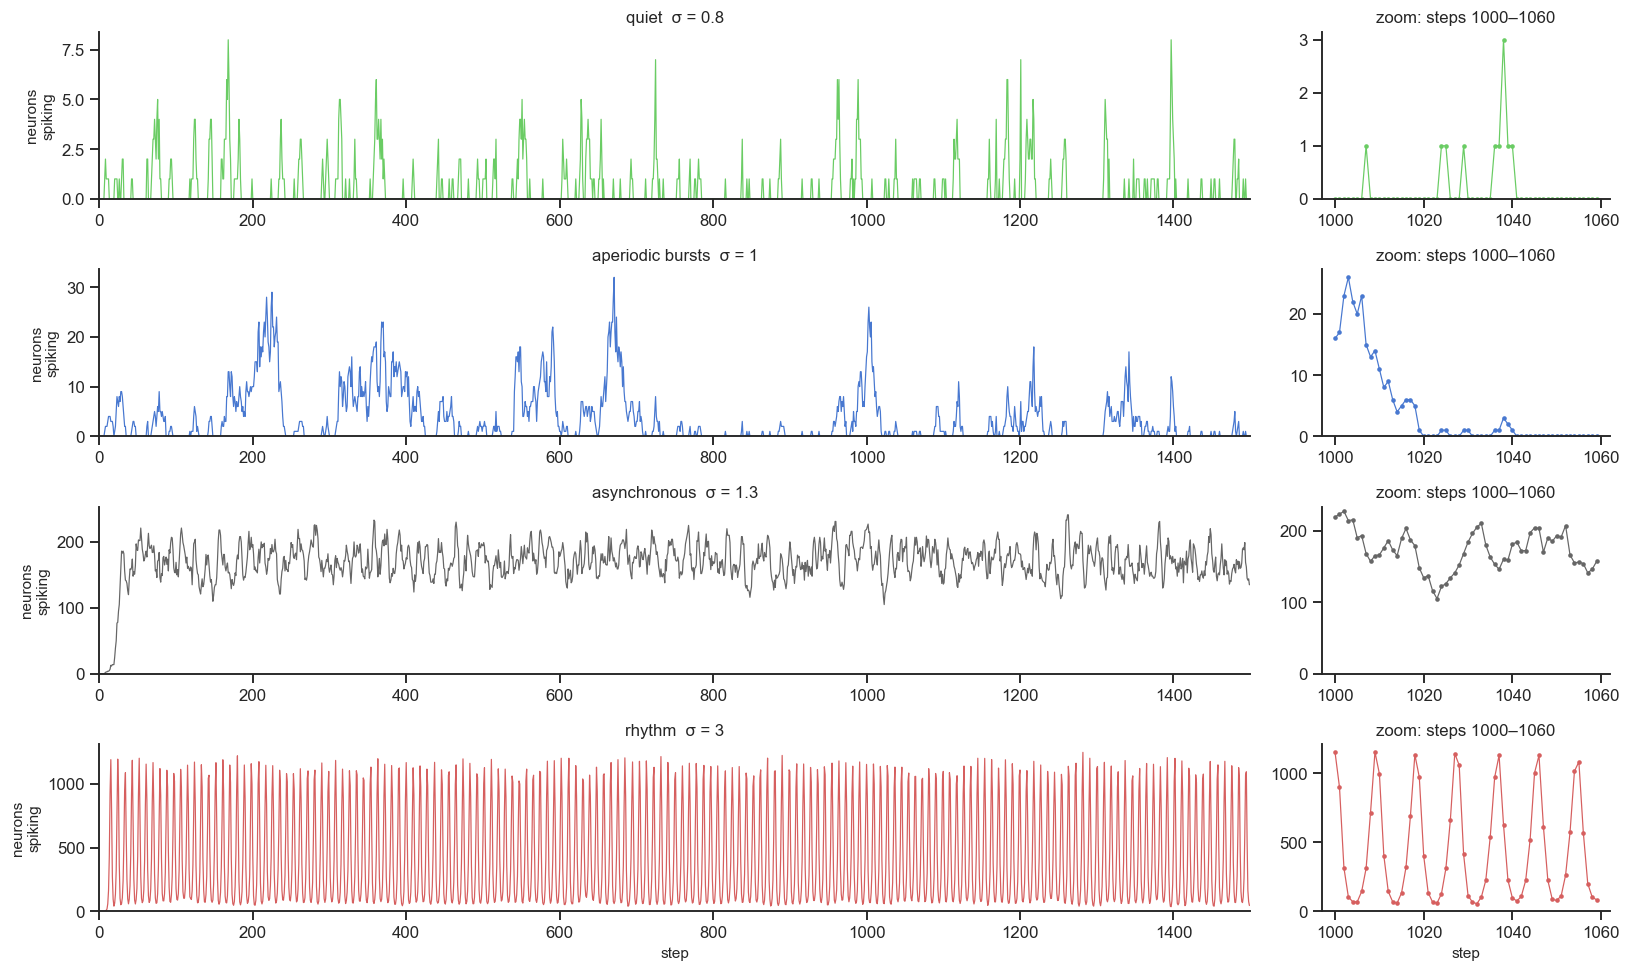

In [10]:
SIDE, N_REF = 64, 4                       # 64 x 64 neurons; refractory for N_REF steps after a spike
N_BIG = SIDE * SIDE

def step_excitable(s, sigma, ext, rng):
    # s: 0 quiet, 1 spiking, 2..N_REF+1 resting. All-to-all: only the number of spiking neurons matters.
    A = (s == 1).sum()
    P_fire = 1 - (1 - ext / len(s)) * (1 - sigma / (len(s) - 1)) ** A
    fire = (s == 0) & (rng.random(len(s)) < P_fire)
    s = np.where(s > 0, (s + 1) % (N_REF + 2), 0)          # spike -> rest -> ... -> quiet
    s[fire] = 1
    return s

def run_excitable(sigma, T=1500, ext=0.1, seed=0):
    rng = np.random.default_rng(seed)
    s = np.zeros(N_BIG, int); frames = []
    for t in range(T):
        s = step_excitable(s, sigma, ext, rng); frames.append(s.copy())
    return np.array(frames)

ONGOING = {"quiet  σ = 0.8": (0.8, "C2"), "aperiodic bursts  σ = 1": (1.0, "C0"),
           "asynchronous  σ = 1.3": (1.3, "0.4"), "rhythm  σ = 3": (3.0, "C3")}
ongoing = {name: run_excitable(sig, seed=4) for name, (sig, c) in ONGOING.items()}

fig, ax = plt.subplots(len(ONGOING), 2, figsize=(15, 9), gridspec_kw=dict(width_ratios=[4, 1]))
for i, (name, (sig, c)) in enumerate(ONGOING.items()):
    A = (ongoing[name] == 1).sum(1)
    ax[i, 0].plot(A, c=c, lw=0.8)
    ax[i, 0].set(ylabel="neurons\nspiking", title=name, xlim=(0, 1500), ylim=(0, None))
    ax[i, 1].plot(np.arange(1000, 1060), A[1000:1060], "o-", c=c, ms=2, lw=0.8)
    ax[i, 1].set(title="zoom: steps 1000–1060", ylim=(0, None))
ax[-1, 0].set_xlabel("step"); ax[-1, 1].set_xlabel("step")
plt.tight_layout()

* **σ = 0.8 (quiet).** Each outside spike starts a tiny cascade that dies at once: a few spikes now and then.
* **σ = 1 (aperiodic bursts).** Outside spikes start cascades of **all sizes**: long silences, then bursts small and
  large at irregular times. This is the border regime of NB06.
* **σ = 1.3 (asynchronous).** Activity sustains itself: a steady fraction of neurons fires at every step, with no
  rhythm.
* **σ = 3 (rhythm).** Each spike recruits so many neurons that most of the network fires together, rests together
  (the refractory period), and fires again as soon as it recovers: a **periodic** population rhythm (zoom), with a
  period set by the resting time.

Same sequence as the active rotators: quiet, aperiodic bursts at the border, then self-sustained activity that becomes
rhythmic when excitation is strong. Two very different models, the same regimes. As in NB06, the aperiodic bursts
appear at the border between silence and self-sustained activity. In section 8 we measure their sizes: they follow a
**power law**.

Watch the 4096 neurons (one cell each):

In [11]:
GRID_CMAP_BIG = ListedColormap(["white", "0.72"] + ["0.72"] * (N_REF - 1) + ["black"])
def big_states(fr):                       # recode: 0 quiet (white), 1..N_REF resting (grey), N_REF+1 spiking (black)
    return np.where(fr == 1, N_REF + 1, np.where(fr > 1, 1, 0)).reshape(SIDE, SIDE)

def ongoing_movie(runs, t0=900, T=120, interval=90):
    names = list(runs)
    fig, ax = plt.subplots(2, len(names), figsize=(14, 5.4), gridspec_kw=dict(height_ratios=[3, 1]))
    ims, curs = [], []
    for j, name in enumerate(names):
        fr = runs[name]
        ims.append(ax[0, j].imshow(big_states(fr[t0]), cmap=GRID_CMAP_BIG, vmin=0, vmax=N_REF + 1, interpolation="nearest"))
        ax[0, j].set(xticks=[], yticks=[], title=name)
        A = (fr[t0:t0 + T] == 1).sum(1)
        ax[1, j].plot(np.arange(t0, t0 + T), A, c=ONGOING[name][1], lw=0.9)
        ax[1, j].set(xlabel="step", ylim=(0, None))
        curs.append(ax[1, j].axvline(t0, c="k", lw=1))
    ax[1, 0].set_ylabel("spiking")
    plt.tight_layout()

    def update(k):
        for im, name, c in zip(ims, names, curs):
            im.set_data(big_states(runs[name][t0 + k])); c.set_xdata([t0 + k] * 2)
        return ims + curs
    anim = animation.FuncAnimation(fig, update, frames=T, interval=interval)
    plt.close(fig)
    return anim

show_movie(ongoing_movie(ongoing), save_as="../figures/videos/nb06b_ongoing_64x64.mp4")

## 7. From a ball of neurons to a sheet of cortex

A real cortex is not all-to-all: each neuron contacts a limited number of others, mostly nearby. To get closer to
experiments, in which a grid of electrodes records a patch of cortex, we place neurons on a **sheet**:

* $60\times60 = 3600$ neurons on a square grid (the edges wrap around, so there is no border);
* each neuron listens to $K=10$ others, picked at random within a radius of 12 sites;
* a spike of one of them makes it fire with probability $p=\sigma/K$, so $\sigma$ is again **the average number of
  children per spike**: the same knob as before;
* after a spike a neuron is **refractory** for 3 steps (states 2, 3, 4) before it can fire again, as real neurons
  have a refractory period;
* an optional **external input**: each resting neuron also fires by itself with probability $1-e^{-h}$ per step
  (spikes coming from the thalamus or other areas).

This is the **Kinouchi–Copelli model** (2006), a probabilistic cellular automaton of *excitable* units
(quiet → spike → refractory → quiet). It is the model in which the functional benefits of section 9 were first
predicted.

In [12]:
L, K, R, N_STATES = 60, 10, 12, 5          # sheet side, inputs per neuron, wiring radius, states (0 quiet, 1 spike, 2-4 refractory)
N_SHEET = L * L

def connect(seed=0):
    # pre[i] = the K neurons that neuron i listens to (random, within distance R; the sheet wraps around)
    rng = np.random.default_rng(seed)
    disk = np.array([(dx, dy) for dx in range(-R, R + 1) for dy in range(-R, R + 1) if 0 < dx**2 + dy**2 <= R**2])
    x, y = np.divmod(np.arange(N_SHEET), L)
    d = disk[rng.integers(len(disk), size=(N_SHEET, K))]
    return ((x[:, None] + d[..., 0]) % L) * L + (y[:, None] + d[..., 1]) % L

pre = connect()


def step_sheet(s, sigma, h, rng):
    # One time step of the sheet. s: state of each neuron (0 quiet, 1 spiking, 2..4 refractory).
    p = sigma / K                                       # each spike causes sigma new spikes on average
    lam = 1 - np.exp(-h)                                # probability of a spike from external input
    m = (s[pre] == 1).sum(axis=1)                       # number of spiking inputs of each neuron
    P = 1 - (1 - lam) * (1 - p) ** m                    # probability to fire now (at least one "yes")
    fire = (s == 0) & (rng.random(N_SHEET) < P)         # only quiet neurons can fire
    s = np.where(s > 0, (s + 1) % N_STATES, 0)          # spike -> refractory -> ... -> quiet
    s[fire] = 1
    return s


def run_sheet(sigma, T, seed=0, h=0.0, start_centre=True):
    rng = np.random.default_rng(seed)
    s = np.zeros(N_SHEET, int)
    if start_centre:
        s[(L // 2) * L + L // 2] = 1
    frames = [s]
    for _ in range(T):
        s = step_sheet(s, sigma, h, rng); frames.append(s)
    return np.array(frames).reshape(-1, L, L)


def pick_sheet(sigma, T, want):
    # choose a random seed whose cascade illustrates the regime (for the movie only)
    for seed in range(300):
        fr = run_sheet(sigma, T, seed)
        act = (fr == 1).reshape(len(fr), -1).sum(1)
        last = np.nonzero(act)[0].max()
        if want == "sub" and 4 <= last <= 15: return fr
        if want == "crit" and 50 <= last < T - 10 and act.sum() > 300: return fr
        if want == "super" and act[-1] > 0: return fr
    return fr

CASES = [(0.7, "sub", "subcritical  σ = 0.7"), (1.0, "crit", "critical  σ = 1"), (1.5, "super", "supercritical  σ = 1.5")]
T_MOV = 120
sheet_runs = [pick_sheet(sig, T_MOV, key) for sig, key, _ in CASES]

In [13]:
SHEET_CMAP = ListedColormap(["#1b1b1b", "#ffd166", "#c0392b", "#7f2a20", "#3d1a15"])

def sheet_movie(runs, titles, interval=80):
    fig, ax = plt.subplots(2, 3, figsize=(10.5, 5.4), gridspec_kw=dict(height_ratios=[3, 1.2]))
    ims, curs = [], []
    for j, (fr, name) in enumerate(zip(runs, titles)):
        ims.append(ax[0, j].imshow(fr[0], cmap=SHEET_CMAP, vmin=0, vmax=N_STATES - 1, interpolation="nearest"))
        ax[0, j].set_title(name, fontsize=10); ax[0, j].axis("off")
        act = (fr == 1).reshape(len(fr), -1).sum(1)
        ax[1, j].plot(act, "k", lw=0.8)
        ax[1, j].set(xlabel="step", ylabel="spiking neurons" if j == 0 else "", yscale="symlog", ylim=(0, N_SHEET))
        curs.append(ax[1, j].axvline(0, c="C3"))
    plt.tight_layout()

    def update(k):
        for im, fr, c in zip(ims, runs, curs):
            im.set_data(fr[k]); c.set_xdata([k, k])
        return ims + curs
    anim = animation.FuncAnimation(fig, update, frames=len(runs[0]), interval=interval)
    plt.close(fig)
    return anim

show_movie(sheet_movie(sheet_runs, [c[2] for c in CASES]), save_as="../figures/videos/nb06b_sheet.mp4")

Each sheet starts from **one spike in the centre**. Yellow = spiking, red to dark red = refractory, black = quiet.
Bottom: number of spiking neurons (log scale).

* **Subcritical**: a short flicker, then silence.
* **Critical**: a sparse cascade that wanders over the sheet, grows and shrinks, and eventually dies, sometimes after
  a long time.
* **Supercritical**: the activity invades the whole sheet and keeps itself going, a bit like a seizure in a
  network with too little inhibition.

## 8. Neuronal avalanches

In 2003, Beggs and Plenz recorded slices of rat cortex with a grid of 60 electrodes. Most of the time the tissue was
quiet. Every now and then, a burst of activity appeared, spread across some electrodes and stopped. They called each
burst a **neuronal avalanche**:

> **avalanche** = a cascade that starts from silence and ends in silence.
> Its **size** $s$ = the total number of spikes; its **duration** = the number of steps.

In our sheet we can make avalanches one at a time: one spike at a random place, run until silence, count. (A
supercritical cascade may never stop, so we stop it after 300 steps and call it a *runaway*.) While doing this we
also count, at every step, how many spikes each generation produced (**descendants / ancestors**), as long as the
cascade is small (fewer than 2% of the neurons active, so that it has not yet filled the sheet). This is how
experimenters estimate $\sigma$ from data, because they cannot measure $p$ directly.

In [14]:
def avalanches(sigma, n_aval, T_max=300, seed=0):
    rng = np.random.default_rng(seed)
    sizes, durations = np.empty(n_aval, int), np.empty(n_aval, int)
    ancestors = descendants = 0
    for k in range(n_aval):
        s = np.zeros(N_SHEET, int); s[rng.integers(N_SHEET)] = 1
        a_prev, size, t = 1, 1, 0
        while t < T_max:
            s = step_sheet(s, sigma, 0.0, rng); t += 1
            a = (s == 1).sum()
            if a_prev < N_SHEET // 50:                  # count generations only while few neurons are active
                ancestors += a_prev; descendants += a
            if a == 0: break
            size += a; a_prev = a
        sizes[k], durations[k] = size, t
    return sizes, durations, descendants / ancestors

AVAL = {}
for sig, key in [(0.8, "sub"), (1.0, "crit"), (1.2, "super")]:
    AVAL[key] = (sig,) + avalanches(sig, 1500, seed=1)
for key, (sig, S, D, est) in AVAL.items():
    print(f"σ = {sig}:  estimated from the cascades σ ≈ {est:.2f};  median size {np.median(S):.0f}, "
          f"largest {S.max()},  runaways {np.mean(D >= 300):.0%}")

σ = 0.8:  estimated from the cascades σ ≈ 0.81;  median size 2, largest 127,  runaways 0%
σ = 1.0:  estimated from the cascades σ ≈ 0.98;  median size 2, largest 3546,  runaways 0%
σ = 1.2:  estimated from the cascades σ ≈ 1.14;  median size 4, largest 42173,  runaways 30%


The estimate "descendants / ancestors" gives back, approximately, the $\sigma$ we put in: a quantity you can compute from a recording
tells you how far the network is from balance. (With real electrodes, which only see a small fraction of the neurons,
this estimate is biased, and correcting for it is an active research topic; see Homework 2.)

Now the sizes. First, on ordinary (linear) axes:

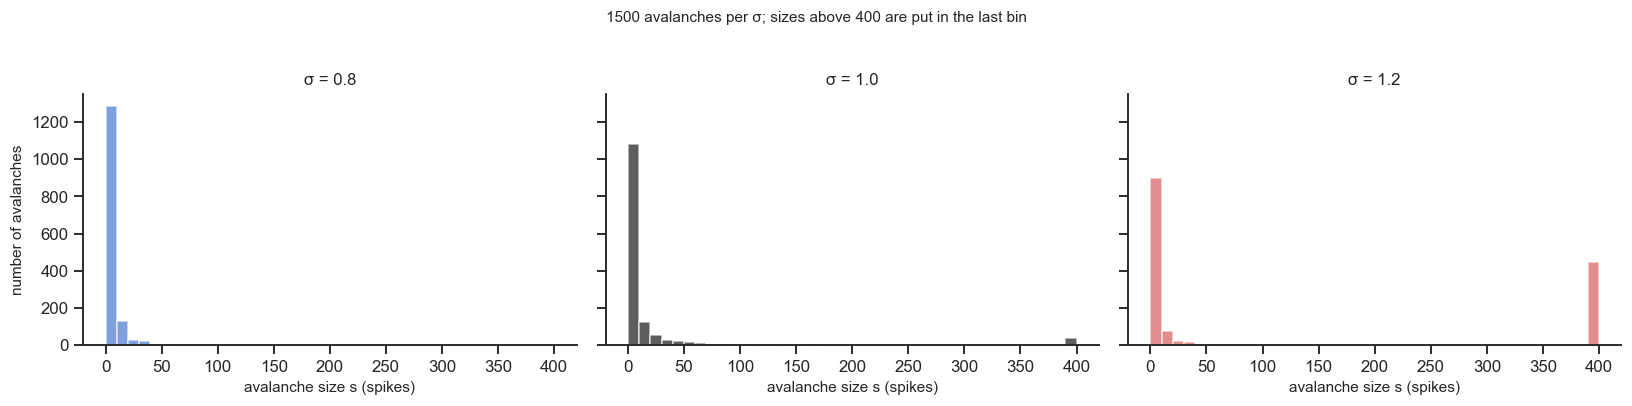

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for j, key in enumerate(["sub", "crit", "super"]):
    sig, S, D, _ = AVAL[key]
    ax[j].hist(np.clip(S, 0, 400), bins=np.arange(0, 410, 10), color=REG[key], alpha=0.7)
    ax[j].set(xlabel="avalanche size s (spikes)", title=f"σ = {sig}")
ax[0].set_ylabel("number of avalanches")
fig.suptitle("1500 avalanches per σ; sizes above 400 are put in the last bin", y=1.02, fontsize=10)
plt.tight_layout()

On linear axes all three look alike: almost all avalanches are small. The interesting part is invisible: the rare
large ones. To see the rare events we use **logarithmic axes**, where each tick is ten times the previous one:

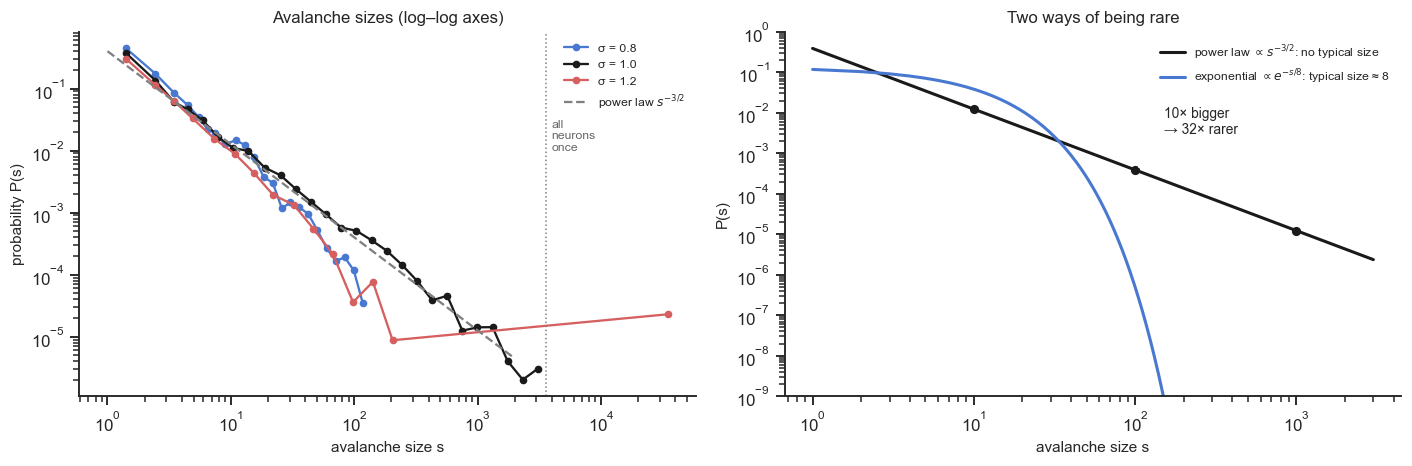

In [16]:
def log_hist(x, n_bins=30):
    edges = np.unique(np.logspace(0, np.log10(x.max() + 1), n_bins).astype(int))
    h, _ = np.histogram(x, edges)
    centre = np.sqrt(edges[:-1] * edges[1:])
    ok = h > 0
    return centre[ok], (h / np.diff(edges) / len(x))[ok]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for key in ["sub", "crit", "super"]:
    sig, S, D, _ = AVAL[key]
    x, P = log_hist(S)
    ax[0].plot(x, P, "o-", ms=4, c=REG[key], label=f"σ = {sig}")
xx = np.logspace(0, 3.3, 10)
ax[0].plot(xx, 0.4 * xx ** -1.5, "--", c="0.5", label=r"power law $s^{-3/2}$")
ax[0].axvline(N_SHEET, c="0.5", ls=":", lw=1); ax[0].text(N_SHEET * 1.1, 1e-2, "all\nneurons\nonce", fontsize=8, color="0.4")
ax[0].set(xscale="log", yscale="log", xlabel="avalanche size s", ylabel="probability P(s)", title="Avalanche sizes (log–log axes)")
ax[0].legend(fontsize=8)

# what a power law means: compare with an exponential decay that has the same small avalanches
s_ = np.arange(1, 3001)
pl = s_ ** -1.5; pl /= pl.sum()
ex = np.exp(-s_ / 8.0); ex /= ex.sum()
ax[1].loglog(s_, pl, c="k", lw=2, label=r"power law $\propto s^{-3/2}$: no typical size")
ax[1].loglog(s_, ex, c=REG["sub"], lw=2, label=r"exponential $\propto e^{-s/8}$: typical size ≈ 8")
for s0 in [10, 100, 1000]:
    ax[1].plot([s0], [pl[s0 - 1]], "ko", ms=5)
ax[1].annotate("10× bigger\n→ 32× rarer", xy=(100, pl[99]), xytext=(150, 3e-3), fontsize=9, arrowprops=dict(arrowstyle="->"))
ax[1].set(ylim=(1e-9, 1), xlabel="avalanche size s", ylabel="P(s)", title="Two ways of being rare")
ax[1].legend(fontsize=8)
plt.tight_layout()

**Left panel, the three regimes.**

* **Subcritical (blue)**: for small sizes it looks like the others, but it is **cut off** early: beyond about a
  hundred spikes the curve plunges (exponentially) and big avalanches practically never happen. The cut-off is a
  **typical maximal size**, and it shrinks the further $\sigma$ is below 1.
* **Supercritical (red)**: two kinds of events. Small fizzles (cascades that died by bad luck in the first steps)
  and **runaways** that light up the whole sheet (the isolated point far to the right). Nothing in between.
* **Critical (black)**: a **straight line** on log–log axes, over three orders of magnitude, with slope $-3/2$:
  $P(s)\propto s^{-3/2}$. This is a **power law**. It bends down only near 3600 spikes, when avalanches start
  to feel the edge of the finite sheet.

**Right panel: what a power law means.** On log–log axes, a straight line means: *every time you make the avalanche
10 times bigger, it becomes the same number of times rarer.* With slope $3/2$: $10^{1.5}\approx 32$ times rarer, from
10 to 100 spikes and again from 100 to 1000. Large avalanches are rare, but not impossible. With an exponential (blue),
each extra spike multiplies the rarity, so an avalanche 100 times the typical size essentially never happens.

**Why is this interesting?** A power law is not just a pretty straight line:

1. **No typical size (scale-free).** The same network, with the same rule, produces tiny local events *and*
   network-wide events, and everything in between. There is no preferred scale. This is the variability of section 3,
   now measured: one spike can lead to any outcome.
2. **A fingerprint you can measure.** In a living brain you cannot measure $p$ or $\sigma$ directly. But you can record
   avalanches. If their sizes follow a power law with exponent close to $3/2$ (and their durations one close to $2$),
   the network behaves as if it were balanced at $\sigma\approx1$. This is how the criticality hypothesis is tested
   (Beggs & Plenz 2003; section 10).
3. **Universality.** The exponent $3/2$ does not depend on the details (number of inputs, refractory period, exact
   coin probabilities). Very different systems at the same kind of transition share the same exponents. This is why a
   model as crude as ours can be compared with real cortex: at criticality, many details stop mattering.

*Caution.* Power laws can also come from other mechanisms, and a straight segment on a log–log plot is easy to
over-interpret. Researchers therefore check several signatures together (size and duration exponents, how size grows
with duration, the shape of avalanches). We do this in NB08 for a network of spiking-like units.

## 9. Why balance pays off: three functional benefits

So far we have described what balanced networks *look like*. Shew & Plenz ask what they are *good for*. They review
three properties of a network that are all best at $\sigma=1$. We measure each of them on our sheet, by doing to the
model what experimenters do to cortex slices: stimulate and record.

### 9.1 Dynamic range: responding to both whispers and shouts

Our senses work over enormous ranges: the eye works from starlight to sunlight (a ratio of about $10^{10}$), the ear
from a whisper to a rock concert. Single sensory neurons saturate over a much smaller range. How can a network do
better than its parts?

**Experiment.** Drive every neuron with external spikes at rate $h$ (from very weak to very strong), and measure the
**response** $F$ = average fraction of neurons spiking per step. The **dynamic range** $\Delta$ is the range of inputs
the network can tell apart: from the input that gives 10% of the maximal response change, $h_{10}$, to the one that
gives 90%, $h_{90}$, in decibels:

$$
\Delta = 10\,\log_{10}\frac{h_{90}}{h_{10}}\qquad(\text{10 dB = a factor 10 in input}).
$$

*(Takes ~20 s.)*

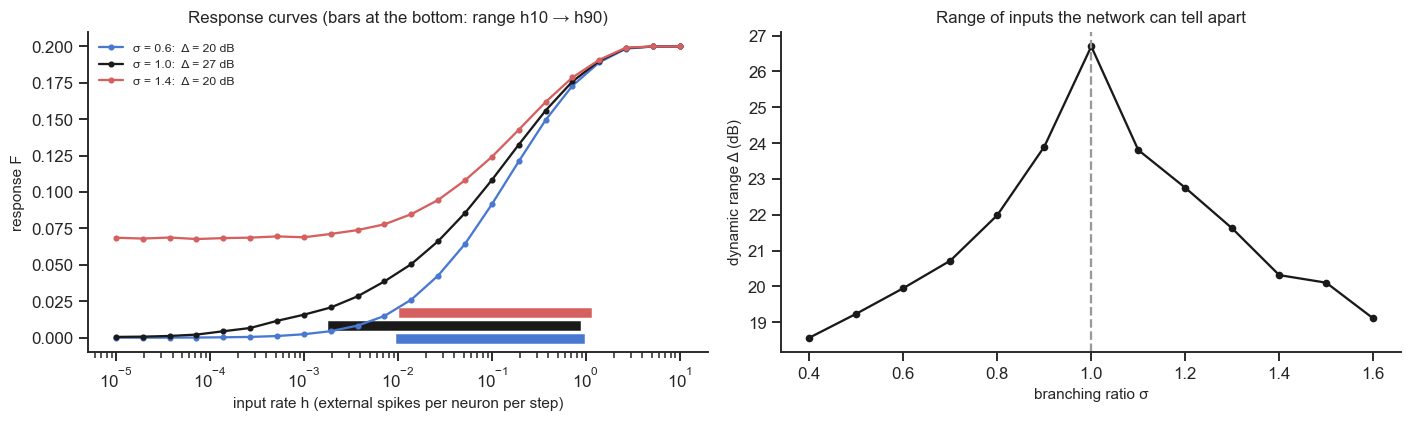

In [17]:
def mean_response(sigma, h, T=250, burn=80, seed=0):
    rng = np.random.default_rng(seed)
    s = rng.integers(0, N_STATES, N_SHEET) * (rng.random(N_SHEET) < 0.2)      # random start
    F = 0.0
    for t in range(T):
        s = step_sheet(s, sigma, h, rng)
        if t >= burn: F += (s == 1).mean()
    return F / (T - burn)

def dynamic_range(F, hs):
    F0, Fmax = F[0], F[-1]
    lh = np.log10(hs)
    h10 = 10 ** np.interp(F0 + 0.1 * (Fmax - F0), F, lh)
    h90 = 10 ** np.interp(F0 + 0.9 * (Fmax - F0), F, lh)
    return 10 * np.log10(h90 / h10), h10, h90

hs = np.logspace(-5, 1, 22)
sig_scan = np.round(np.arange(0.4, 1.61, 0.1), 2)
RESP = {sig: np.array([mean_response(sig, h) for h in hs]) for sig in sig_scan}
DR = {sig: dynamic_range(RESP[sig], hs)[0] for sig in sig_scan}

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, (sig, c) in enumerate([(0.6, REG["sub"]), (1.0, REG["crit"]), (1.4, REG["super"])]):
    D, h10, h90 = dynamic_range(RESP[sig], hs)
    ax[0].plot(hs, RESP[sig], "o-", ms=3, c=c, label=f"σ = {sig}:  Δ = {D:.0f} dB")
    ax[0].axvspan(h10, h90, ymin=0.03 + 0.04 * i, ymax=0.055 + 0.04 * i, color=c)     # the range h10 -> h90
ax[0].set(xscale="log", xlabel="input rate h (external spikes per neuron per step)", ylabel="response F",
          title="Response curves (bars at the bottom: range h10 → h90)")
ax[0].legend(fontsize=8, loc="upper left")
ax[1].plot(sig_scan, [DR[s] for s in sig_scan], "ko-", ms=4)
ax[1].axvline(1, c="0.6", ls="--")
ax[1].set(xlabel="branching ratio σ", ylabel="dynamic range Δ (dB)", title="Range of inputs the network can tell apart")
plt.tight_layout()

* **Subcritical (blue)**: a weak input causes a few spikes that die immediately. The network only "notices" an input
  when it is strong enough to drive many neurons directly. **Weak inputs are lost.**
* **Supercritical (red)**: the network is already active by itself (even with no input it keeps firing, the high
  starting value of the curve). A weak input is drowned in this ongoing activity, and strong inputs quickly saturate
  it. **Strong inputs all look the same.**
* **Critical (black)**: a weak input is **amplified** (each external spike can trigger an avalanche of any size),
  while strong inputs do not saturate too early. The response curve is stretched over the widest range of inputs.

The dynamic range peaks at $\sigma=1$ (Kinouchi & Copelli 2006). Shew et al. (2009) confirmed it in cortex cultures:
the dynamic range was largest in untreated cultures that showed neuronal avalanches, and it dropped when drugs pushed
the balance either way.

### 9.2 Information transmission: getting the message across

Dynamic range looks at one number (how strong was the input?). More generally we ask: **if I only see the response,
how much can I tell about the stimulus?** This is measured by the **mutual information** (MI) between stimulus and
response, in bits. A simple way to read it: $2^{\text{MI}}$ is roughly the number of stimuli that can be told apart
reliably from the response. With 8 equally likely stimuli the maximum is 3 bits.

**Experiment** (like Shew et al. 2011). We kick a strip of neurons on the left edge of the sheet with 8 stimulus
strengths (fraction of the strip made to fire), 40 times each, on top of a weak background activity. We record from
a strip **half a sheet away** and count its spikes in the next 15 steps. The signal has to travel through many
neurons to get there. *(~10 s.)*

In [18]:
COL = np.arange(N_SHEET) % L
SOURCE = COL < 6                           # input strip (left edge)
TARGET = (COL >= 27) & (COL < 33)          # recording strip, half a sheet away

def transmit(sigma, f, rng, h=1e-4, T=15):
    s = np.zeros(N_SHEET, int)
    for _ in range(20): s = step_sheet(s, sigma, h, rng)        # weak background activity
    s[SOURCE & (s == 0) & (rng.random(N_SHEET) < f)] = 1        # the stimulus
    out = 0
    for _ in range(T):
        s = step_sheet(s, sigma, h, rng); out += (s[TARGET] == 1).sum()
    return out

def mutual_information(resp, n_bins=8):
    # resp[i, k] = response to stimulus i in trial k. Plug-in estimate, responses binned in n_bins groups.
    edges = np.unique(np.quantile(resp, np.linspace(0, 1, n_bins + 1)[1:-1]))
    b = np.digitize(resp, edges)
    joint = np.array([[np.mean(row == k) for k in range(b.max() + 1)] for row in b]) / len(resp)
    ps, pr = joint.sum(1, keepdims=True), joint.sum(0, keepdims=True)
    nz = joint > 0
    return np.sum(joint[nz] * np.log2(joint[nz] / (ps * pr)[nz]))

stims = np.logspace(-2.5, 0, 8)            # fraction of the input strip kicked
sig_mi = np.round(np.arange(0.5, 1.61, 0.1), 2)
RESP_T = {}
for sig in sig_mi:
    rng = np.random.default_rng(1)
    RESP_T[sig] = np.array([[transmit(sig, f, rng) for _ in range(40)] for f in stims])
MI = {sig: mutual_information(RESP_T[sig]) for sig in sig_mi}

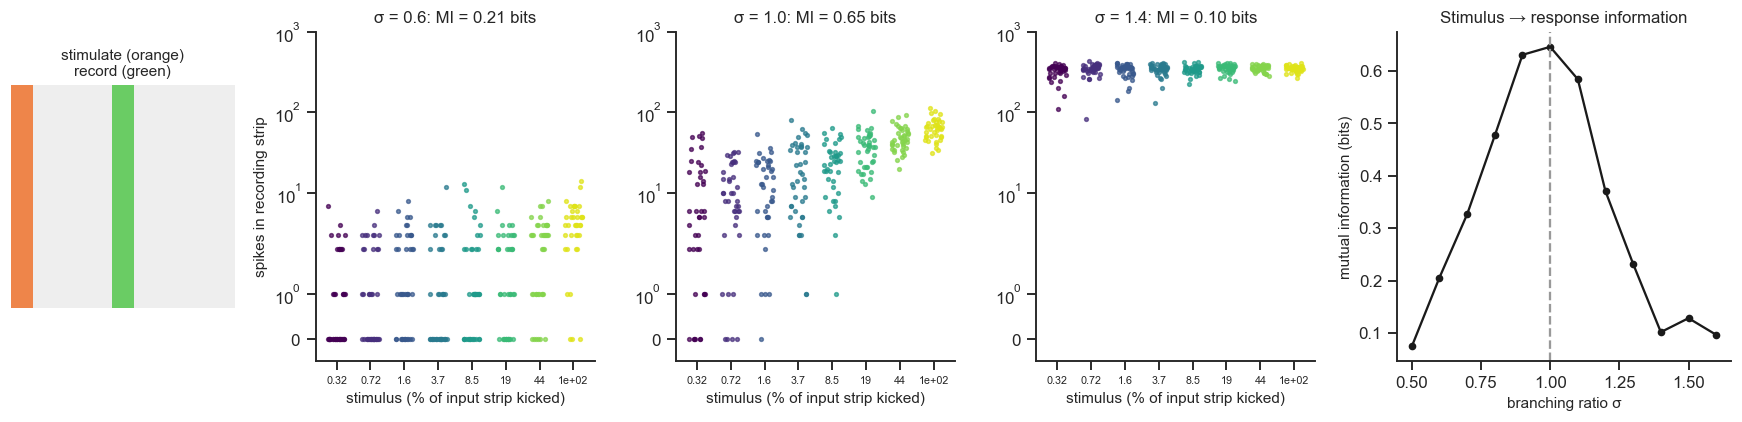

In [19]:
fig = plt.figure(figsize=(16, 4))
gs = fig.add_gridspec(1, 5, width_ratios=[0.8, 1, 1, 1, 1.2])
a0 = fig.add_subplot(gs[0])
sheet = np.zeros(N_SHEET); sheet[SOURCE] = 1; sheet[TARGET] = 2
a0.imshow(sheet.reshape(L, L), cmap=ListedColormap(["#eeeeee", "C1", "C2"])); a0.axis("off")
a0.set_title("stimulate (orange)\nrecord (green)", fontsize=10)
cmap8 = plt.cm.viridis(np.linspace(0, 0.95, len(stims)))
jit = np.random.default_rng(0).uniform(-0.25, 0.25, 40)
for j, (sig, key) in enumerate([(0.6, "sub"), (1.0, "crit"), (1.4, "super")]):
    a = fig.add_subplot(gs[j + 1])
    r = RESP_T[sig]
    for i in range(len(stims)):
        a.scatter(i + jit, r[i], s=6, color=cmap8[i], alpha=0.7)
    a.set(xticks=range(len(stims)), xticklabels=[f"{100 * f:.2g}" for f in stims], yscale="symlog",
          xlabel="stimulus (% of input strip kicked)", ylabel="spikes in recording strip" if j == 0 else "",
          title=f"σ = {sig}: MI = {MI[sig]:.2f} bits", ylim=(-0.5, 1000))
    a.tick_params(axis="x", labelsize=7)
a = fig.add_subplot(gs[4])
a.plot(sig_mi, [MI[s] for s in sig_mi], "ko-", ms=4); a.axvline(1, c="0.6", ls="--")
a.set(xlabel="branching ratio σ", ylabel="mutual information (bits)", title="Stimulus → response information")
plt.tight_layout()

Middle panels: each dot is one trial; columns are the 8 stimuli (weak, dark → strong, yellow). Good transmission
means the columns are **at different heights**: from the response you can tell which stimulus was given.

* **Subcritical**: the signal dies before reaching the recording strip. Most responses are 0 or a few spikes,
  whatever the stimulus.
* **Supercritical**: background activity and any stimulus ignite the whole sheet; the recording strip fires a lot
  regardless. All columns sit at the same height.
* **Critical**: the response grows with the stimulus over the whole range. Neighbouring columns still overlap (the response is
  variable), but weak, medium and strong stimuli are clearly told apart.

So mutual information also peaks near $\sigma=1$. Shew et al. (2011) found the same in cortex cultures. They also
found that, near balance, the response to a *repeated identical* stimulus was the most variable. Variable and
informative at the same time: the network uses its wide repertoire of responses to encode the stimulus.

### 9.3 Information capacity: a large repertoire of patterns

The last property is about the **repertoire**: how many different activity patterns can the network produce? A network
that can only be "all off" or "all on" can represent very little; one with hundreds of distinguishable patterns can
represent much more.

**Experiment** (like Haldeman & Beggs 2005; Shew et al. 2011). Place 9 "electrodes" on the sheet (a 3×3 grid, each
reading a small 4×4 patch). Start avalanches from single spikes at random places; for each one, record its
**footprint**: which electrodes it reached in the first 100 steps (a pattern of 9 bits: on/off).

The size of the repertoire is measured by the **entropy** of the footprints (Shannon):

$$
H = -\sum_i P_i\,\log_2 P_i ,
$$

where $P_i$ is how often footprint $i$ occurs. Example from the paper: if 128 different patterns occur, all equally
often, $H=\log_2 128 = 7$ bits. If one pattern occurs almost always, $H\approx0$. *(~20 s.)*

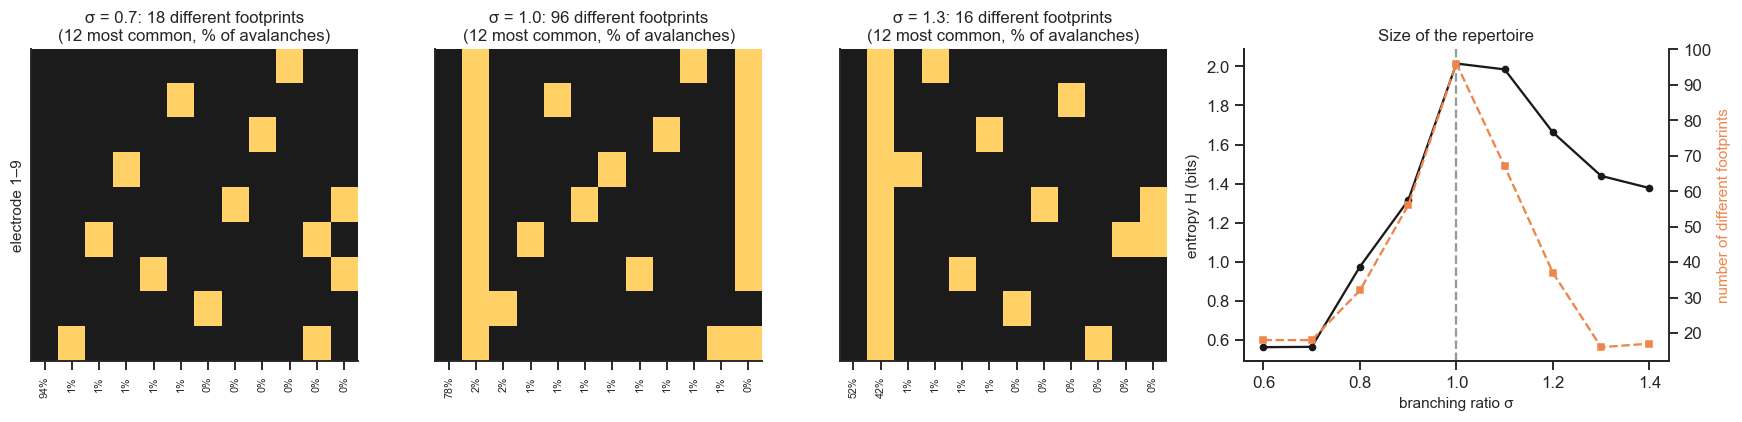

In [20]:
cx = np.arange(10, 60, 20)                 # electrode centres: a 3x3 grid
ELEC = np.array([[(x + dx) * L + (y + dy) for dx in range(-2, 2) for dy in range(-2, 2)] for x in cx for y in cx])

def footprints(sigma, n_aval=1200, W=100, seed=0):
    rng = np.random.default_rng(seed)
    pats = np.zeros((n_aval, 9), bool)
    for k in range(n_aval):
        s = np.zeros(N_SHEET, int); s[rng.integers(N_SHEET)] = 1
        for t in range(W):
            s = step_sheet(s, sigma, 0.0, rng)
            on = s == 1
            if not on.any(): break
            pats[k] |= on[ELEC].any(1)
    return pats

def entropy(pats):
    _, counts = np.unique(pats, axis=0, return_counts=True)
    P = counts / counts.sum()
    return -(P * np.log2(P)).sum(), len(counts)

sig_h = np.round(np.arange(0.6, 1.41, 0.1), 2)
FP = {sig: footprints(sig) for sig in sig_h}
H = {sig: entropy(FP[sig]) for sig in sig_h}

fig = plt.figure(figsize=(16, 4))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.3])
for j, (sig, key) in enumerate([(0.7, "sub"), (1.0, "crit"), (1.3, "super")]):
    a = fig.add_subplot(gs[j])
    u, c = np.unique(FP[sig], axis=0, return_counts=True)
    order = np.argsort(-c)[:12]
    a.imshow(u[order].reshape(-1, 9).T, cmap=ListedColormap(["#1b1b1b", "#ffd166"]), aspect="auto")
    a.set(xticks=range(len(order)), xticklabels=[f"{100 * c[o] / c.sum():.0f}%" for o in order], yticks=[],
          ylabel="electrode 1–9" if j == 0 else "",
          title=f"σ = {sig}: {H[sig][1]} different footprints\n(12 most common, % of avalanches)")
    a.tick_params(axis="x", labelsize=7, rotation=90)
a = fig.add_subplot(gs[3])
a.plot(sig_h, [H[s][0] for s in sig_h], "ko-", ms=4, label="entropy H (bits)")
a2 = a.twinx(); a2.plot(sig_h, [H[s][1] for s in sig_h], "s--", c="C1", ms=4); a2.set_ylabel("number of different footprints", color="C1")
a2.spines["right"].set_visible(True)
a.axvline(1, c="0.6", ls="--")
a.set(xlabel="branching ratio σ", ylabel="entropy H (bits)", title="Size of the repertoire")
plt.tight_layout()

Left panels: the 12 most common footprints (columns; yellow = electrode reached) and how often each occurred.

* **Subcritical**: almost every avalanche dies before reaching any electrode: the "all off" footprint dominates. Low
  entropy.
* **Supercritical**: cascades either fizzle or invade everything: two footprints ("none" and "all") dominate. Low
  entropy again.
* **Critical**: avalanches of all sizes reach different combinations of electrodes: the largest repertoire.

In this small model the repertoire is largest around $\sigma\approx1$ (with a shorter observation window the peak moves
slightly into the supercritical side; try it in Homework 4). Shew et al. (2011) explain the experimental peak with
a competition between two effects: entropy needs **activity** (silent electrodes carry no information), but it also
needs electrodes that are **not all doing the same thing** (correlations reduce the number of distinct patterns). Too
little excitation gives too little activity; too little inhibition gives activity that is too correlated. Balance
gives enough of both.

## 10. Back to real brains: how do you test this?

To test whether the cortex benefits from being balanced, Shew & Plenz list two requirements:

1. **A way to change the balance** (to change $p$). Experimenters use drugs: blocking inhibitory GABA$_A$ receptors
   (picrotoxin) pushes towards the supercritical side, with runaway, epilepsy-like activity; blocking excitatory
   AMPA/NMDA receptors (DNQX/AP5) pushes towards the subcritical side.
2. **A way to know how close to balance you are.** This is the hard part: $p$ cannot be measured in a piece of cortex,
   and the tissue may compensate for the drug without asking for permission. The solution is the fingerprint of
   section 8: record **neuronal avalanches** and measure how close their size distribution is to the critical power
   law (Shew et al. defined a statistic $\kappa$, equal to 1 at criticality).

Using these two tools, untreated cortex cultures showed avalanches ($\kappa\approx1$) *and* the largest dynamic
range, information transmission and pattern entropy; drugs in either direction reduced all three. Recordings from
awake monkeys also gave $\kappa\approx1$.

What does $p$ stand for in a real brain? Everything that sets **how likely one spike is to cause another**: the
balance of excitation and inhibition, the excitability of neurons, synaptic strengths, neuromodulators. Many of these
are regulated by **homeostatic** mechanisms (Homework 5), one proposed reason why the cortex might stay close to
$\sigma=1$.

*Not everything is settled.* Real networks have inhibition, loops, external input and noise, and the evidence often
points to a cortex operating *close to* rather than exactly at criticality, with the distance to it changing with
brain state (wake, sleep, anaesthesia). The two-day course comes back to this:

* **NB07**: bifurcations, the mathematics of "close to a transition";
* **NB08**: avalanches in a network of spiking-like units, where they appear only at a special kind of
  synchronization transition.

## 11. Take-home

| | subcritical $\sigma<1$ | critical $\sigma=1$ | supercritical $\sigma>1$ |
|---|---|---|---|
| one spike causes on average | fewer than one | exactly one | more than one |
| activity after a single spike | dies quickly | reverberates, highly variable | takes over and sustains itself |
| avalanche sizes | typical size, exponential tail | **power law** $s^{-3/2}$, no typical size | fizzles or runaways |
| dynamic range | weak inputs lost | **largest** | strong inputs saturate |
| information transmission | signal dies on the way | **largest** | signal drowned |
| repertoire (entropy) | mostly silent | **largest** | mostly all-on |
| in cortex, e.g. | excitation blocked | untreated cortex, awake monkeys | inhibition blocked (epileptiform) |

* "A neuron activates another with probability $p$" lumps many biological factors into one number. What matters for
  the network is $\sigma = p\times$(number of targets): **how many spikes one spike causes**.
* Activity grows like $\sigma^t$: a **branching process**. Balance is $\sigma=1$, i.e. $p\approx1/N$.
* $\sigma=1$ is a **phase transition** between silence and self-sustained activity, the bifurcation point of the mean
  field.
* At the transition, avalanches have **no typical size** (power laws). This is the fingerprint that experiments
  look for, because $p$ itself cannot be measured.
* Balance is useful: the widest **dynamic range**, the best **transmission** and the richest **repertoire**.

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. **Bigger networks.** Using `run_counts`, find the balanced $p$ for all-to-all networks of $N=10$, $100$, $1000$
   neurons (the $p$ at which the survival curve of section 5 drops). Plot it against $N$ on log–log axes. What line do
   you expect?
2. **Estimating σ from a recording.** For the sheet at $\sigma=0.9$, $1.0$, $1.1$ with weak input ($h=10^{-4}$),
   record the number of spiking neurons $A(t)$ for 5000 steps and estimate $\sigma$ as the slope of $A(t+1)$ against
   $A(t)$. Now pretend your electrodes see only 5% of the neurons (count only a random 5%) and repeat. What happens to
   the estimate? (See Priesemann et al. 2014; Wilting & Priesemann 2018.)
3. **Durations.** Plot the distribution of avalanche **durations** at $\sigma=1$ (they are returned by `avalanches`).
   Is it a power law? Compare with $T^{-2}$. Then plot the average size of avalanches of duration $T$ against $T$ (the
   theory predicts $\langle s\rangle\propto T^2$).
4. **Observation window.** Repeat section 9.3 with a window of $W=20$ steps and with 16 electrodes (4×4). Where is the
   peak of the entropy now? Why can a short window favour slightly supercritical networks?
5. **Self-organization.** Let the network tune itself: start the sheet at $\sigma=0.5$ or $\sigma=1.5$, run one
   avalanche (stop runaways after 300 steps), and after each avalanche change $\sigma$ by a small amount: up if it
   died in fewer than 5 steps, down if it was a runaway. Plot $\sigma$ over 2000 avalanches. Where does it settle?
6. **Local wiring.** Set the wiring radius to $R=2$ (only immediate neighbours) and redo the survival curve on the
   sheet. Is the transition still at $\sigma=1$? Why do neighbours sharing their inputs "waste" spikes? (Hint: a
   neuron hit by two spikes at once fires only once.)

### References
* Shew WL, Plenz D (2013). The functional benefits of criticality in the cortex. *The Neuroscientist* 19:88–100.
  (The thought experiment of sections 2–3 and the three benefits of section 9.)
* Beggs JM, Plenz D (2003). Neuronal avalanches in neocortical circuits. *J Neurosci* 23:11167–11177.
* Kinouchi O, Copelli M (2006). Optimal dynamical range of excitable networks at criticality. *Nat Phys* 2:348–351.
* Shew WL, Yang H, Petermann T, Roy R, Plenz D (2009). Neuronal avalanches imply maximum dynamic range in cortical
  networks at criticality. *J Neurosci* 29:15595–15600.
* Shew WL, Yang H, Yu S, Roy R, Plenz D (2011). Information capacity and transmission are maximized in balanced
  cortical networks with neuronal avalanches. *J Neurosci* 31:55–63.
* Haldeman C, Beggs JM (2005). Critical branching captures activity in living neural networks and maximizes the
  number of metastable states. *Phys Rev Lett* 94:058101.
* Harris TE (1963). *The Theory of Branching Processes*. Springer.
* Priesemann V, Wibral M, Valderrama M, et al. (2014). Spike avalanches in vivo suggest a driven, slightly subcritical
  brain state. *Front Syst Neurosci* 8:108.
* Wilting J, Priesemann V (2018). Inferring collective dynamical states from widely unobserved systems.
  *Nat Commun* 9:2325.
* Muñoz MA (2018). Colloquium: Criticality and dynamical scaling in living systems. *Rev Mod Phys* 90:031001.